<a href="https://colab.research.google.com/github/wUssopp/Eksploracja-Danych/blob/main/lab03_otwarte_dane_odstajace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [2]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [3]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Wgraj plik szkolnictwo_wysze.csv:


Saving szkolnictwo_wysze.csv to szkolnictwo_wysze.csv


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [4]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [5]:
df = pd.read_csv(PLIK_LODZ, sep=";", encoding="utf-8-sig")

display(df.head())
print("wymiary:", df.shape)
print("\ntypy kolumn:")
print(df.dtypes)
print("\nnazwy kolumn:", df.columns.tolist())

,name,rok,wartość,zmienna
0,Szkolnictwo wyższe,2012,22,uczelnie
1,Szkolnictwo wyższe,2013,22,uczelnie
2,Szkolnictwo wyższe,2014,23,uczelnie
3,Szkolnictwo wyższe,2015,21,uczelnie
4,Szkolnictwo wyższe,2016,20,uczelnie


wymiary: (65, 4)

typy kolumn:
name       object
rok         int64
wartość     int64
zmienna    object
dtype: object

nazwy kolumn: ['name', 'rok', 'wartość', 'zmienna']


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separatorem jest **średnik `;`** (przecinek dziesiętny nie występuje - wszystkie wartości to liczby całkowite). Kolumna `wartość` ma typ **liczbowy `int64`**, a `rok` także `int64`; `name` i `zmienna` to tekst. Polskie znaki w nazwach kolumn (`wartość`) i w wartościach (`mężczyźni`, `ogółem`) wczytały się poprawnie, bo plik jest w UTF-8. Jedyny haczyk: plik zaczyna się od znacznika **BOM** (niewidoczny znak `﻿` przed `name`) - dlatego użyłem `encoding="utf-8-sig"`, żeby pierwsza kolumna nazywała się `name`, a nie `﻿name`. Dane mają 65 wierszy i 4 kolumny.

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [6]:
# jakie są zmienne i ile mają wierszy?
print(df["zmienna"].value_counts())
print("\nliczba lat:", df["rok"].nunique(), f"({df['rok'].min()}–{df['rok'].max()})")

# format szeroki (pivot)
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka.columns.name = None
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64

liczba lat: 13 (2012–2024)


,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [7]:
roznica = szeroka["kobiety"] + szeroka["mężczyźni"] - szeroka["ogółem"]
display(roznica.to_frame("(kobiety + mężczyźni) − ogółem").T)
print("Czy dane są spójne we wszystkich latach?", (roznica == 0).all())

rok,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
(kobiety + mężczyźni) − ogółem,0,0,0,0,0,0,0,0,0,0,0,0,0


Czy dane są spójne we wszystkich latach? True


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [8]:
# statystyki opisowe
display(szeroka.describe())

# zmiana procentowa 2012 -> 2024
zmiana_proc = (szeroka.loc[2024] / szeroka.loc[2012] - 1) * 100
display(zmiana_proc.round(1).to_frame("zmiana 2012 → 2024 [%]"))

# nowe kolumny
szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
szeroka

,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
count,13.00,13.00,13.00,13.00,13.00
mean,17780.54,43010.92,28793.92,71804.85,19.54
std,3522.40,5391.05,3524.63,8900.65,2.44
min,14082.00,38146.00,25710.00,64272.00,15.00
25%,14756.00,39170.00,26049.00,65297.00,18.00
50%,17046.00,39958.00,26297.00,66002.00,20.00
75%,19835.00,45584.00,30769.00,76353.00,22.00
max,24825.00,55265.00,36281.00,91546.00,23.00


,zmiana 2012 → 2024 [%]
absolwenci ogółem,-41.30
kobiety,-30.20
mężczyźni,-29.10
ogółem,-29.80
uczelnie,-31.80


,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie,udzial_kobiet,studenci_na_uczelnie
rok,,,,,,,
2012,24825,55265,36281,91546,22,0.60,4161.18
2013,22590,50007,33464,83471,22,0.60,3794.14
2014,21343,48220,32456,80676,23,0.60,3507.65
2015,19835,45584,30769,76353,21,0.60,3635.86
2016,17662,44053,29908,73961,20,0.60,3698.05
2017,19281,42990,29029,72019,22,0.60,3273.59
2018,17046,39312,26253,65565,20,0.60,3278.25
2019,15819,38146,26297,64443,19,0.59,3391.74
2020,14082,39170,26155,65325,18,0.60,3629.17


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

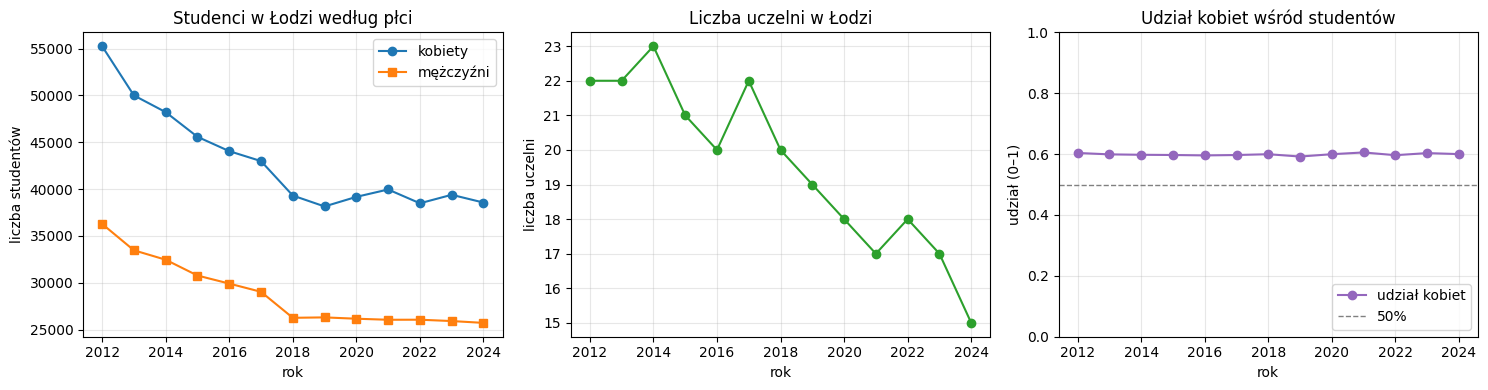

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
lata = szeroka.index

# wykres 1 - kobiety i mężczyźni
ax = axes[0]
ax.plot(lata, szeroka["kobiety"], marker="o", label="kobiety")
ax.plot(lata, szeroka["mężczyźni"], marker="s", label="mężczyźni")
ax.set(title="Studenci w Łodzi według płci", xlabel="rok", ylabel="liczba studentów")
ax.legend()

# wykres 2 - uczelnie
ax = axes[1]
ax.plot(lata, szeroka["uczelnie"], marker="o", color="tab:green")
ax.set(title="Liczba uczelni w Łodzi", xlabel="rok", ylabel="liczba uczelni")

# wykres 3 - udział kobiet
ax = axes[2]
ax.plot(lata, szeroka["udzial_kobiet"], marker="o", color="tab:purple", label="udział kobiet")
ax.axhline(0.5, ls="--", color="gray", lw=1, label="50%")
ax.set(title="Udział kobiet wśród studentów", xlabel="rok", ylabel="udział (0–1)", ylim=(0, 1))
ax.legend(loc="lower right")

for ax in axes:
    ax.set_xticks(lata[::2])
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012-2024?

*Odpowiedź:* Liczba studentów w Łodzi spadła z 91,5 tys. w 2012 r. do 64,3 tys. w 2024 r. (o ok. 30%), przy czym spadek był najszybszy do 2018-2019 r., a potem liczba ustabilizowała się na poziomie ok. 64-66 tys.; absolwentów ubyło jeszcze więcej (-41%). Liczba uczelni zmniejszyła się z 22-23 do 15 (-32%), więc na jedną uczelnię przypada dziś średnio ok. 4,3 tys. studentów - najwięcej w całym okresie. Struktura płci się nie zmieniła: kobiety przez cały czas stanowią ok. 60% studentów, a dane są w pełni spójne (kobiety + mężczyźni = ogółem w każdym roku).

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** *Przyrost naturalny w Łodzi* (kategoria Demografia -> Ludność; dostawca danych: Bank Danych Lokalnych GUS, publikujący: Urząd Miasta Łodzi; lata 1995–2025) · **link:** [otwarte.miasto.lodz.pl/ludnosc](https://otwarte.miasto.lodz.pl/ludnosc/), plik [przyrost-naturalny-w-odzi.csv](https://otwarte.miasto.lodz.pl/wp-content/uploads/2026/01/przyrost-naturalny-w-odzi.csv) · **data pobrania:** 27.10.2026

In [10]:
PLIK_MOJ = "przyrost_naturalny_w_lodzi.csv"
URL_MOJ = "https://otwarte.miasto.lodz.pl/wp-content/uploads/2026/01/przyrost-naturalny-w-odzi.csv"

if not Path(PLIK_MOJ).exists():
    try:
        import urllib.request
        urllib.request.urlretrieve(URL_MOJ, PLIK_MOJ)
        print("Pobrano plik z portalu.")
    except Exception as e:
        print("Nie udało się pobrać automatycznie:", e)
        upewnij_sie_ze_jest(PLIK_MOJ)

with open(PLIK_MOJ, encoding="utf-8") as f:
    for _ in range(4):
        print(repr(f.readline()))

proba = pd.read_csv(PLIK_MOJ, sep=";")
print("\ntypy przy samym sep=';':")
print(proba.dtypes)
print("\nwartości ze spacją w środku:", proba["wartość"].str.contains(" ").sum())
print(proba.loc[proba["wartość"].str.contains(" "), "wartość"].head(3).tolist())

Pobrano plik z portalu.
'\ufeffname;rok;wartość;zmienne\n'
'Ludność stan;1995;6 149;ogółem urodzenia żywe\n'
'Ludność stan;1996;5 987;ogółem urodzenia żywe\n'
'Ludność stan;1997;5 848;ogółem urodzenia żywe\n'

typy przy samym sep=';':
name       object
rok         int64
wartość    object
zmienne    object
dtype: object

wartości ze spacją w środku: 19
['6 149', '5 987', '5 848']


,name,rok,wartość,zmienne
0,Ludność stan,1995,6149,ogółem urodzenia żywe
1,Ludność stan,1996,5987,ogółem urodzenia żywe
2,Ludność stan,1997,5848,ogółem urodzenia żywe
3,Ludność stan,1998,5471,ogółem urodzenia żywe
4,Ludność stan,1999,5344,ogółem urodzenia żywe


wymiary: (93, 4)
name       object
rok         int64
wartość     int64
zmienne    object
dtype: object 

zmienne
ogółem urodzenia żywe        31
ogółem przyrost naturalny    31
ogółem zgony                 31
Name: count, dtype: int64 

braki w kolumnach:
name       0
rok        0
wartość    0
zmienne    0
dtype: int64 

przyrost = urodzenia − zgony we wszystkich latach? True
lata bez przerw? True (1995–2025, 31 lat)


,urodzenia,zgony,przyrost,urodzenia_na_zgon
count,31.00,31.00,31.00,31.00
mean,5729.35,10475.55,-4746.19,0.55
std,623.99,682.26,764.08,0.06
min,4038.00,9184.00,-6661.00,0.44
25%,5457.00,10113.00,-5263.50,0.51
50%,5848.00,10367.00,-4852.00,0.55
75%,6091.50,10914.50,-4128.50,0.60
max,6892.00,12090.00,-3520.00,0.65


,zmiana 1995 → 2025 [%]
urodzenia,-34.30
zgony,-20.40
przyrost,-4.60


najwięcej urodzeń: 2009 | najwięcej zgonów: 2021 | najgorszy przyrost: 2021 | najlepszy przyrost: 2016


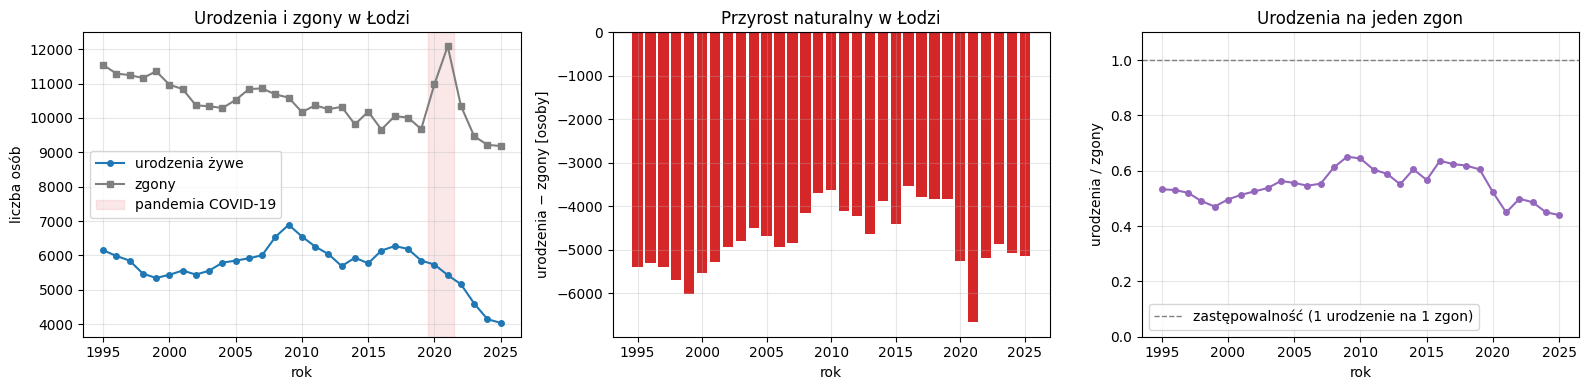

In [11]:
moj = pd.read_csv(PLIK_MOJ, sep=";", encoding="utf-8-sig", thousands=" ")
display(moj.head())
print("wymiary:", moj.shape)
print(moj.dtypes, "\n")
print(moj["zmienne"].value_counts(), "\n")

print("braki w kolumnach:")
print(moj.isna().sum(), "\n")

moja_szeroka = (moj.pivot(index="rok", columns="zmienne", values="wartość")
                   .rename(columns={"ogółem urodzenia żywe": "urodzenia",
                                    "ogółem zgony": "zgony",
                                    "ogółem przyrost naturalny": "przyrost"})
                   [["urodzenia", "zgony", "przyrost"]])
moja_szeroka.columns.name = None

roznica_moj = moja_szeroka["urodzenia"] - moja_szeroka["zgony"] - moja_szeroka["przyrost"]
print("przyrost = urodzenia − zgony we wszystkich latach?", (roznica_moj == 0).all())
print("lata bez przerw?", (moja_szeroka.index.to_series().diff().dropna() == 1).all(),
      f"({moja_szeroka.index.min()}–{moja_szeroka.index.max()}, {len(moja_szeroka)} lat)")

moja_szeroka["urodzenia_na_zgon"] = moja_szeroka["urodzenia"] / moja_szeroka["zgony"]
display(moja_szeroka.describe())
zm = (moja_szeroka.loc[2025, ["urodzenia", "zgony", "przyrost"]]
      / moja_szeroka.loc[1995, ["urodzenia", "zgony", "przyrost"]] - 1) * 100
display(zm.round(1).to_frame("zmiana 1995 → 2025 [%]"))
print("najwięcej urodzeń:", moja_szeroka["urodzenia"].idxmax(),
      "| najwięcej zgonów:", moja_szeroka["zgony"].idxmax(),
      "| najgorszy przyrost:", moja_szeroka["przyrost"].idxmin(),
      "| najlepszy przyrost:", moja_szeroka["przyrost"].idxmax())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
lata = moja_szeroka.index

ax = axes[0]
ax.plot(lata, moja_szeroka["urodzenia"], marker="o", ms=4, label="urodzenia żywe")
ax.plot(lata, moja_szeroka["zgony"], marker="s", ms=4, color="tab:gray", label="zgony")
ax.axvspan(2019.5, 2021.5, color="tab:red", alpha=0.1, label="pandemia COVID-19")
ax.set(title="Urodzenia i zgony w Łodzi", xlabel="rok", ylabel="liczba osób")
ax.legend()

ax = axes[1]
ax.bar(lata, moja_szeroka["przyrost"], color="tab:red")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Przyrost naturalny w Łodzi", xlabel="rok", ylabel="urodzenia − zgony [osoby]")

ax = axes[2]
ax.plot(lata, moja_szeroka["urodzenia_na_zgon"], marker="o", ms=4, color="tab:purple")
ax.axhline(1, ls="--", color="gray", lw=1, label="zastępowalność (1 urodzenie na 1 zgon)")
ax.set(title="Urodzenia na jeden zgon", xlabel="rok", ylabel="urodzenia / zgony", ylim=(0, 1.1))
ax.legend(loc="lower left")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

✍️ **Wnioski:**

*Wczytanie:* plik ma separator `;`, kodowanie UTF-8 z BOM i - co najważniejsze - **niespójny zapis liczb**: dla lat 1995-2013 urodzenia zapisano ze spacją jako separatorem tysięcy (`6 149`), a dla późniejszych bez niej (`5935`). Przy samym `sep=";"` cała kolumna `wartość` wczytuje się więc jako tekst; pomaga `thousands=" "`. Dane są w formacie **długim** (93 wiersze = 3 zmienne x 31 lat), bez braków, i są spójne: w każdym roku przyrost = urodzenia - zgony.

*Treść:* przez cały okres 1995-2025 przyrost naturalny w Łodzi był **ujemny**, co roku umierało o 3,5-6,7 tys. osób więcej, niż się rodziło, a na jeden zgon przypadało tylko 0,45-0,65 urodzenia. Urodzenia rosły do maksimum 6,9 tys. w 2009 r., a od 2017 r. szybko spadają w 2025 r. urodziło się tylko 4,0 tys. dzieci, o 34% mniej niż w 1995 r. Najgorszy był 2021 r. (12,1 tys. zgonów w czasie pandemii, przyrost -6,7 tys.); po pandemii zgonów jest mniej, ale przez malejącą liczbę urodzeń przyrost wciąż wynosi ok. -5 tys. rocznie.

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [12]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

,age,bmi,avg_glucose_level
count,3000.00,3000.00,3000.00
mean,45.25,26.29,134.00
std,20.83,15.88,181.27
min,0.67,-5.20,-21.40
25%,28.00,21.28,85.59
50%,49.00,24.70,101.40
75%,63.00,28.88,127.43
max,80.00,105.60,1254.60


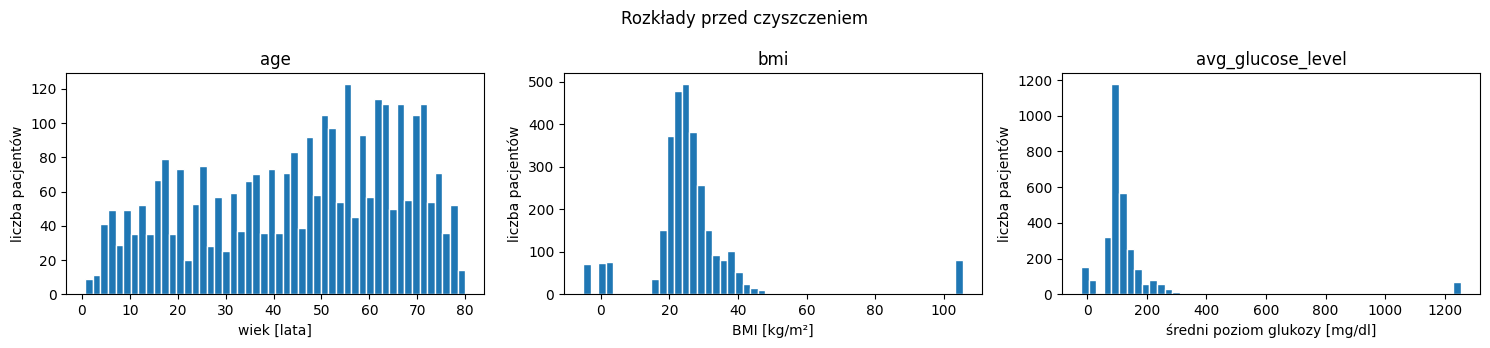

In [13]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]
OPISY = {"age": "wiek [lata]", "bmi": "BMI [kg/m²]", "avg_glucose_level": "średni poziom glukozy [mg/dl]"}

# statystyki opisowe
display(pacjenci[LICZBOWE].describe())

# histogramy
def histogramy(dane, tytul):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
    for ax, kol in zip(axes, LICZBOWE):
        ax.hist(dane[kol].dropna(), bins=50, edgecolor="white")
        ax.set(title=kol, xlabel=OPISY[kol], ylabel="liczba pacjentów")
    fig.suptitle(tytul)
    plt.tight_layout()
    plt.show()

histogramy(pacjenci, "Rozkłady przed czyszczeniem")

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:*  **Wiek** 0,67-80 lat, oba końce są możliwe (0,67 roku to ok. 8-miesięczne niemowlę).
- **BMI** min -5,2 - **niemożliwe** (BMI = masa / wzrost², nie może być ujemne ani bliskie zera; realne minimum u żywego człowieka to ok. 10-12). Max 105,6 - praktycznie niespotykane, przy takiej skali danych traktujemy jako błąd.
- **Średnia glukoza** min -21,4 mg/dl - **niemożliwe** (stężenie nie może być ujemne). Max 1254,6 mg/dl - jako *średni, długotrwały* poziom niemożliwe (takie wartości zdarzają się najwyżej w pojedynczym pomiarze w stanie zagrożenia życia).

Na histogramach widać też, że błędne wartości tworzą osobne „słupki” daleko od reszty - to pierwsza wskazówka, że to kody błędów, a nie pacjenci.

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [14]:
# maski
zle_bmi = pacjenci["bmi"].notna() & ~pacjenci["bmi"].between(10, 60)
zla_glukoza = pacjenci["avg_glucose_level"].notna() & ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = pacjenci["age"].notna() & ~pacjenci["age"].between(0, 120)
niemozliwe = zle_bmi | zla_glukoza | zly_wiek

# liczebności
display(pd.Series({"bmi": zle_bmi.sum(),
                   "avg_glucose_level": zla_glukoza.sum(),
                   "age": zly_wiek.sum(),
                   "pacjenci z ≥ 1 niemożliwą wartością": niemozliwe.sum()},
                  name="liczba").to_frame())

print("niemożliwe BMI:", pacjenci.loc[zle_bmi, "bmi"].value_counts().to_dict())
print("niemożliwa glukoza:", pacjenci.loc[zla_glukoza, "avg_glucose_level"].value_counts().to_dict())

# zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan

,liczba
bmi,300
avg_glucose_level,300
age,0
pacjenci z ≥ 1 niemożliwą wartością,560


niemożliwe BMI: {105.6: 80, 3.4: 76, 0.0: 74, -5.2: 70}
niemożliwa glukoza: {-21.4: 78, 5.0: 78, 0.0: 74, 1254.6: 70}


,age,bmi,avg_glucose_level
count,3000.00,2700.00,2700.00
mean,45.25,26.12,116.84
std,20.83,5.84,44.45
min,0.67,13.57,44.76
25%,28.00,21.94,89.47
50%,49.00,24.98,103.09
75%,63.00,28.85,127.84
max,80.00,47.62,332.91


braki po czyszczeniu: {'age': 0, 'bmi': 300, 'avg_glucose_level': 300}


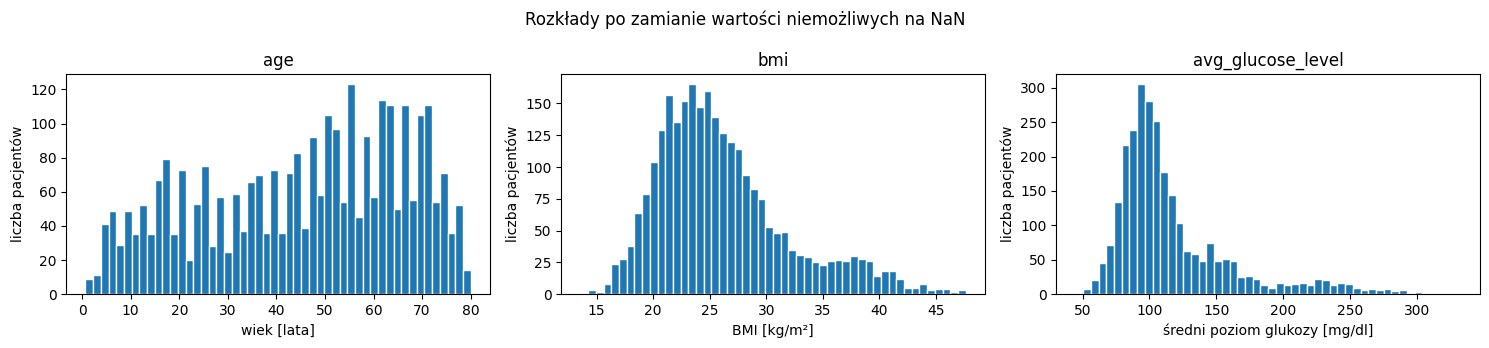

In [15]:
display(pacjenci[LICZBOWE].describe())
print("braki po czyszczeniu:", pacjenci[LICZBOWE].isna().sum().to_dict())
histogramy(pacjenci, "Rozkłady po zamianie wartości niemożliwych na NaN")

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

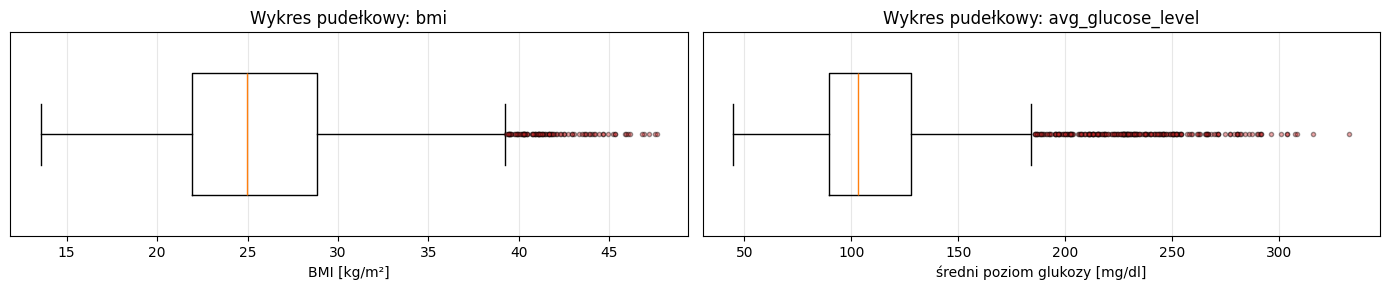

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

for ax, kol in zip(axes, ["bmi", "avg_glucose_level"]):
    ax.boxplot(pacjenci[kol].dropna(), orientation="horizontal", widths=0.6,
               flierprops=dict(marker="o", markersize=3, alpha=0.4, markerfacecolor="tab:red"))
    ax.set(title=f"Wykres pudełkowy: {kol}", xlabel=OPISY[kol], yticks=[])
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

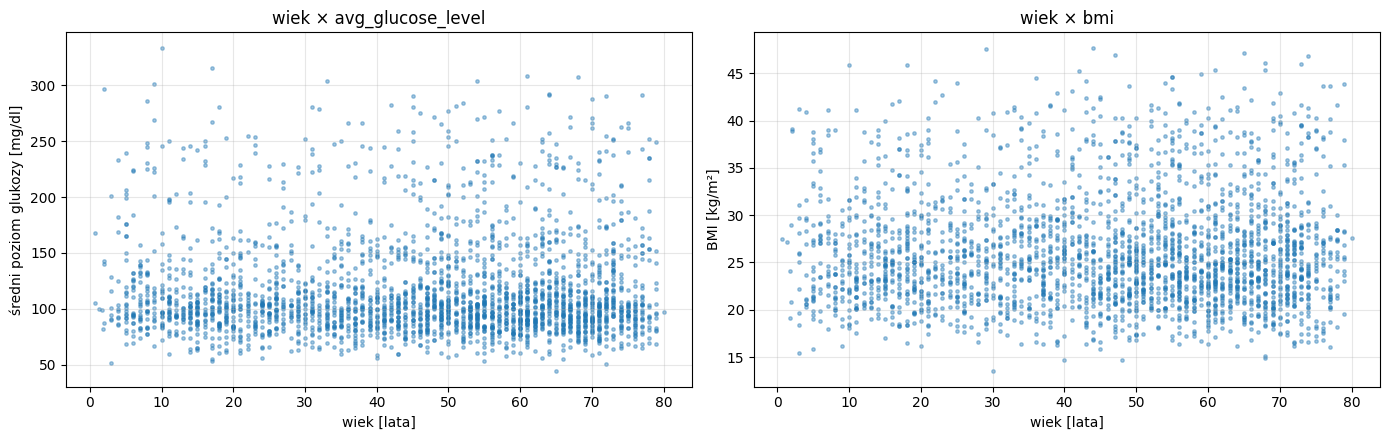

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for ax, kol in zip(axes, ["avg_glucose_level", "bmi"]):
    ax.scatter(pacjenci["age"], pacjenci[kol], s=6, alpha=0.4)
    ax.set(title=f"wiek × {kol}", xlabel=OPISY["age"], ylabel=OPISY[kol])
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:* 1. Więcej punktów poza wąsami ma **glukoza** (235, wobec 100 dla BMI). W obu zmiennych leżą one **tylko po prawej stronie** pudełka (wartości wysokie) - po lewej nie ma żadnych, bo oba rozkłady są prawoskośne.

*Odpowiedź:* 2. Wysokie wartości glukozy występują **w każdym wieku**, mniej więcej równomiernie - od dzieci po 80-latków. 10-latek ze średnią glukozą > 300 mg/dl w prawdziwych danych byłby bardzo podejrzany (oznaczałby ciężką, nieleczoną cukrzycę - możliwe, ale bardzo rzadkie), podczas gdy u 70-latka z cukrzycą typu 2 taki poziom jest dużo bardziej prawdopodobny. Sama liczba nie jest *niemożliwa*, więc nie traktujemy jej jak błędu automatycznie - taki przypadek warto **oznaczyć i zweryfikować** (np. z innymi danymi pacjenta). To, że w tych danych wysoka glukoza nie zależy od wieku, to raczej cecha generatora danych syntetycznych niż obraz rzeczywistości.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [18]:
def maska_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def maska_z(s, prog=3):
    z = (s - s.mean()) / s.std()
    return z.abs() > prog

def maska_mad(s, prog=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    if mad == 0:
        return pd.Series(False, index=s.index)
    zm = 0.6745 * (s - med) / mad
    return zm.abs() > prog

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [19]:
metody = {
    "IQR 1,5": lambda s: maska_iqr(s, 1.5),
    "IQR 3": lambda s: maska_iqr(s, 3),
    "z-score |z|>3": maska_z,
    "MAD |z_m|>3,5": maska_mad,
}
porownanie = pd.DataFrame({nazwa: {kol: f(pacjenci[kol]).sum() for kol in LICZBOWE}
                           for nazwa, f in metody.items()})
porownanie["skośność"] = pacjenci[LICZBOWE].skew()
porownanie

,"IQR 1,5",IQR 3,z-score |z|>3,"MAD |z_m|>3,5",skośność
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* Wszystkie te metody zakładają rozkład mniej więcej **symetryczny**. Glukoza jest silnie **prawoskośna** (skośność 1,8): ma gęste „ciało” ok. 80-130 mg/dl i długi prawy ogon do 333 mg/dl. IQR i MAD mierzą rozrzut tylko w środku rozkładu, więc cały ogon jest dla nich „odstający” (235 i 223 obserwacje, czyli ok. 9% pacjentów). Z-score używa średniej i odchylenia standardowego, które ten sam ogon zawyża (s ≈ 44), więc próg x̄ + 3s ≈ 250 mg/dl leży wysoko i łapie tylko 62 obserwacje - to efekt maskowania. Wiek ma rozkład szeroki, ograniczony (0,67-80) i lekko lewoskośny (-0,33), bez żadnego ogona: granice IQR to [−24,5; 115,5] lat, więc żadna wartość nie może ich przekroczyć. Wniosek: najpierw histogram i skośność, potem wybór metody - przy prawoskośnych danych lepiej najpierw zlogarytmować.

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

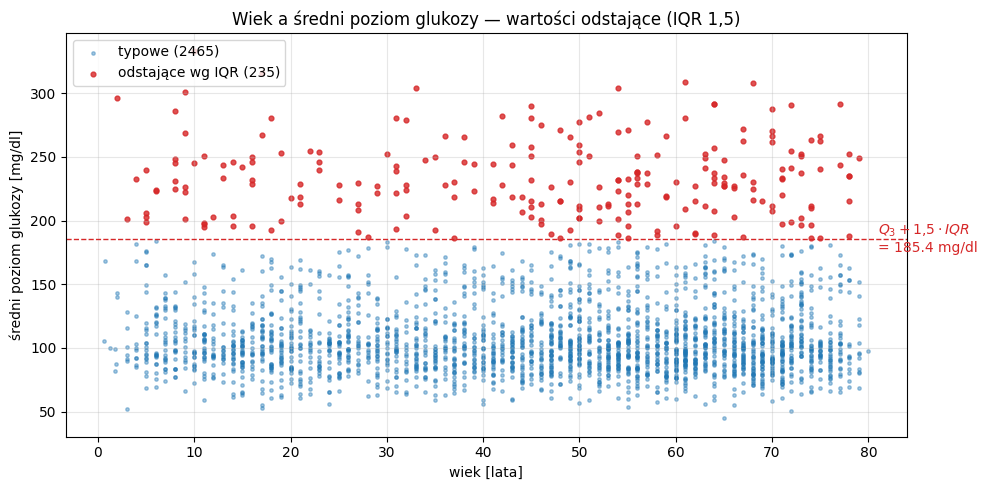

punkty nad linią: 235
punkty poza wąsami wykresu pudełkowego: 235


In [20]:
from matplotlib.cbook import boxplot_stats

glukoza = pacjenci["avg_glucose_level"]
q1, q3 = glukoza.quantile([0.25, 0.75])
gorna = q3 + 1.5 * (q3 - q1)
odst_glu = maska_iqr(glukoza)
typowe = ~odst_glu & glukoza.notna()

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(pacjenci.loc[typowe, "age"], glukoza[typowe], s=6, alpha=0.4,
           color="tab:blue", label=f"typowe ({typowe.sum()})")
ax.scatter(pacjenci.loc[odst_glu, "age"], glukoza[odst_glu], s=12, alpha=0.8,
           color="tab:red", label=f"odstające wg IQR ({odst_glu.sum()})")
ax.axhline(gorna, ls="--", color="tab:red", lw=1)
ax.text(81, gorna, f"$Q_3 + 1{{,}}5 \\cdot IQR$\n= {gorna:.1f} mg/dl", va="center", ha="left", color="tab:red")
ax.set(title="Wiek a średni poziom glukozy — wartości odstające (IQR 1,5)",
       xlabel=OPISY["age"], ylabel=OPISY["avg_glucose_level"])
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("punkty nad linią:", (glukoza > gorna).sum())
print("punkty poza wąsami wykresu pudełkowego:", len(boxplot_stats(glukoza.dropna())[0]["fliers"]))

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

,liczba_pacjentow,odsetek_udarow
avg_glucose_level,,
glukoza odstająca (IQR),235,0.22
pozostali,2465,0.21


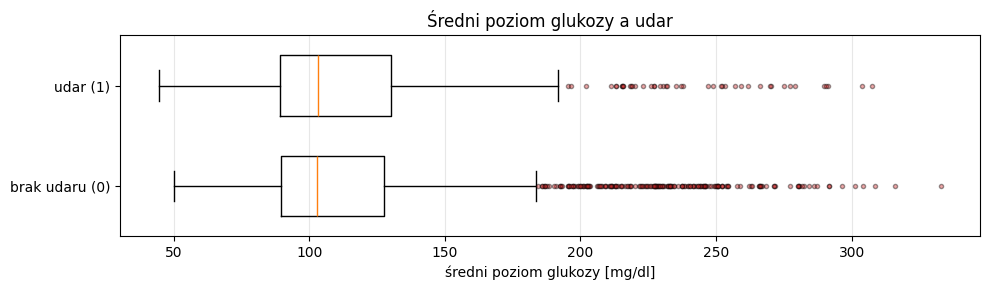

mediana glukozy: {0: 103.1, 1: 103.3}


In [21]:
# odsetek udarów w obu grupach
ma_glukoze = pacjenci["avg_glucose_level"].notna()
grupa = odst_glu[ma_glukoze].map({True: "glukoza odstająca (IQR)", False: "pozostali"})
display(pacjenci.loc[ma_glukoze].groupby(grupa)["stroke"]
        .agg(liczba_pacjentow="count", odsetek_udarow="mean"))

# boxplot glukozy w podziale na stroke
fig, ax = plt.subplots(figsize=(10, 3))
dane_bp = [pacjenci.loc[pacjenci["stroke"] == k, "avg_glucose_level"].dropna() for k in (0, 1)]
ax.boxplot(dane_bp, orientation="horizontal", tick_labels=["brak udaru (0)", "udar (1)"], widths=0.6,
           flierprops=dict(marker="o", markersize=3, alpha=0.4, markerfacecolor="tab:red"))
ax.set(title="Średni poziom glukozy a udar", xlabel=OPISY["avg_glucose_level"])
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
print("mediana glukozy:", pacjenci.groupby("stroke")["avg_glucose_level"].median().round(1).to_dict())

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* **Nie.** Wartości do ok. 330 mg/dl są biologicznie możliwe, więc to nie błędy, tylko prawy ogon rozkładu (9% pacjentów). W tych syntetycznych danych odsetek udarów jest w obu grupach praktycznie taki sam (ok. 22%), a mediany glukozy u osób z udarem i bez są równe (ok. 103 mg/dl) - czyli tu glukoza akurat nie niesie informacji o udarze. Ale w danych rzeczywistych wysoka glukoza jest znanym czynnikiem ryzyka udaru i właśnie ci pacjenci byliby najbardziej informatywni - usunięcie ich wycięłoby sygnał i model nie umiałby przewidywać dla pacjentów z grupy ryzyka. Lepiej je zostawić, ewentualnie zlogarytmować glukozę, użyć modelu odpornego (np. drzewa) albo dodać kolumnę-flagę.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [22]:
# tabela krzyżowa
display(pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"], margins=True))

# maski
dziecko_pali = ((pacjenci["work_type"] == "children")
                & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"]))
maluch_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "student")
print("dziecko_pali:", dziecko_pali.sum(), "| maluch_student:", maluch_student.sum())

display(pacjenci.loc[dziecko_pali | maluch_student,
                     ["patient_id", "age", "work_type", "smoking_status", "ever_married"]]
        .sort_values("age"))

smoking_status,Unknown,formerly smoked,never smoked,smokes,All
work_type,,,,,
Govt_job,16,63,94,67,240
Never_worked,1,30,36,35,102
Private,76,440,585,445,1546
Self-employed,18,137,166,131,452
children,17,0,274,15,306
student,22,67,190,75,354
All,150,737,1345,768,3000


dziecko_pali: 15 | maluch_student: 1


,patient_id,age,work_type,smoking_status,ever_married
52,A582477,1.80,student,formerly smoked,False
361,A843508,2.00,children,smokes,False
578,A161666,3.00,children,smokes,False
797,A427670,5.00,children,smokes,False
942,A929594,8.00,children,smokes,False
782,A383975,9.00,children,smokes,False
111,A678646,9.00,children,smokes,False
600,A623587,10.00,children,smokes,False
2389,A367897,11.00,children,smokes,False
987,A105353,11.00,children,smokes,False


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* **Nie.** IQR i z-score działają na jednej zmiennej *liczbowej* i mierzą odległość od jej środka. Tu błąd siedzi w zmiennych kategorycznych, a każda z nich osobno jest zupełnie typowa: `children` ma 306 pacjentów, `smokes` aż 768. Także wiek tych dzieci (2-14 lat) mieści się w rozkładzie wieku bez problemu. Niemożliwa jest dopiero **kombinacja** wartości - to wykrywa tabela krzyżowa i reguły z wiedzy dziedzinowej. Podejrzane jest zresztą samo ułożenie tabeli: wśród dzieci 15 „pali”, ale 0 „paliło kiedyś” - to wygląda na celowo wstrzyknięte błędy. Maluch-student (1,8 roku) ma dodatkowo status „formerly smoked”, czyli dwie niemożliwe kombinacje naraz.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [23]:
from scipy.stats import chi2

X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=X.shape[1])
odlegli = d2 > prog

print(f"pacjentów bez braków: {len(X)}")
print(f"próg χ²(3), kwantyl 0,99: {prog:.2f}")
print(f"przekracza próg: {odlegli.sum()}")

print("\nnajwiększy udział w d²:")
print((Z ** 2)[odlegli].idxmax(axis=1).value_counts())

pacjentów bez braków: 2440
próg χ²(3), kwantyl 0,99: 11.34
przekracza próg: 73

największy udział w d²:
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

skośność glukozy: 1.78 → po log: 0.89
odległych przed logarytmem: 73, po logarytmie: 31
największy udział w d²_log: {'bmi': 22, 'avg_glucose_level': 9}


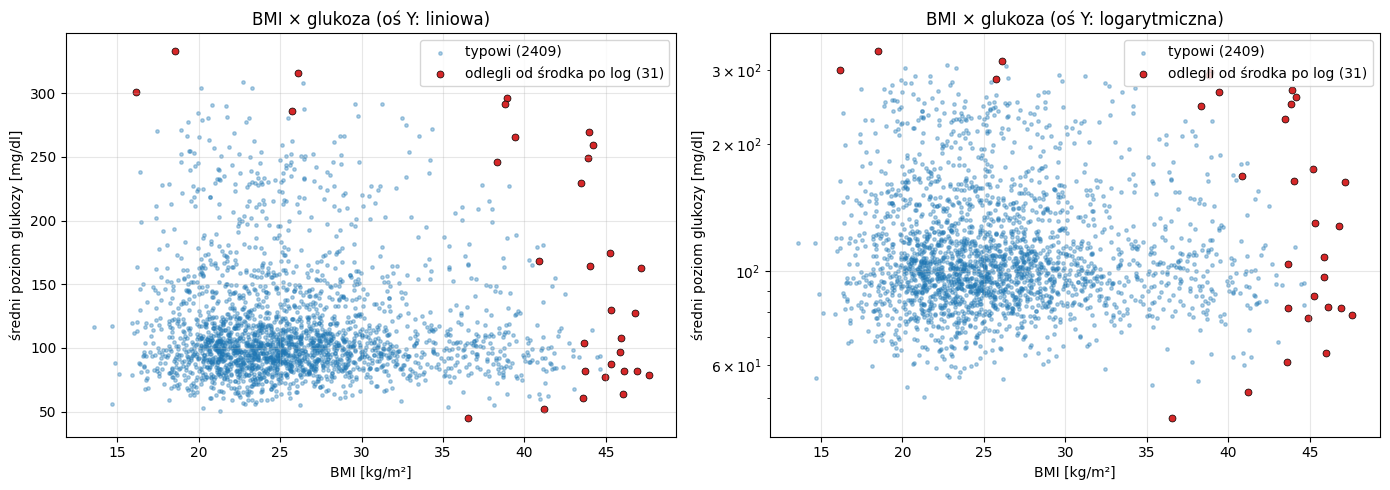

,age,bmi,avg_glucose_level
age,1.00,0.02,0.01
bmi,0.02,1.00,-0.02
avg_glucose_level,0.01,-0.02,1.00


Mahalanobis: 31 odległych, wspólnych z euklidesową: 30, korelacja D² z d²: 0.9997


In [24]:

print(f"skośność glukozy: {X['avg_glucose_level'].skew():.2f} → po log: {np.log(X['avg_glucose_level']).skew():.2f}")
X_log = X.assign(avg_glucose_level=np.log(X["avg_glucose_level"]))
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
odlegli_log = d2_log > prog
print(f"odległych przed logarytmem: {odlegli.sum()}, po logarytmie: {odlegli_log.sum()}")
print("największy udział w d²_log:", (Z_log ** 2)[odlegli_log].idxmax(axis=1).value_counts().to_dict())


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, skala in zip(axes, ["linear", "log"]):
    ax.scatter(X.loc[~odlegli_log, "bmi"], X.loc[~odlegli_log, "avg_glucose_level"],
               s=6, alpha=0.35, color="tab:blue", label=f"typowi ({(~odlegli_log).sum()})")
    ax.scatter(X.loc[odlegli_log, "bmi"], X.loc[odlegli_log, "avg_glucose_level"],
               s=25, color="tab:red", edgecolor="black", lw=0.5,
               label=f"odlegli od środka po log ({odlegli_log.sum()})")
    ax.set_yscale(skala)
    ax.set(title=f"BMI × glukoza (oś Y: {'liniowa' if skala == 'linear' else 'logarytmiczna'})",
           xlabel=OPISY["bmi"], ylabel=OPISY["avg_glucose_level"])
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(X.corr())

S_inv = np.linalg.inv(np.cov(Z_log.T))
D2_maha = pd.Series(np.einsum("ij,jk,ik->i", Z_log.values, S_inv, Z_log.values), index=Z_log.index)
print(f"Mahalanobis: {(D2_maha > prog).sum()} odległych, wspólnych z euklidesową: "
      f"{((D2_maha > prog) & odlegli_log).sum()}, korelacja D² z d²: {np.corrcoef(D2_maha, d2_log)[0, 1]:.4f}")

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* **Praktycznie nic.** Korelacje między wiekiem, BMI i glukozą wynoszą |r| ≤ 0,023, więc macierz kowariancji wystandaryzowanych cech jest prawie macierzą jednostkową, a wtedy odległość Mahalanobisa sprowadza się do euklidesowej (elipsa staje się okręgiem). Sprawdziłem to liczbowo: Mahalanobis wskazuje 31 pacjentów (tyle samo co euklidesowa), 30 z nich jest wspólnych, a korelacja obu odległości to 0,9997. Mahalanobis przydaje się dopiero, gdy cechy są skorelowane i punkt może „iść pod prąd” trendu - jak Jakub w przykładzie z wykładu.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [25]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.01, random_state=0)
etykiety = iso.fit_predict(X_log)
odst_iso = pd.Series(etykiety == -1, index=X_log.index)

print("Isolation Forest wskazuje:", odst_iso.sum())
print("odległość d2_log wskazuje:", odlegli_log.sum())
print("wspólnych:", (odst_iso & odlegli_log).sum())

Isolation Forest wskazuje: 25
odległość d2_log wskazuje: 31
wspólnych: 19


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [26]:
flagi = pd.DataFrame(index=oryginal.index)
flagi["niemozliwa_wartosc"] = niemozliwe
flagi["glukoza_iqr"] = maska_iqr(pacjenci["avg_glucose_level"])
flagi["nielogiczna_kategoria"] = dziecko_pali | maluch_student
flagi["odlegly_od_srodka"] = odlegli_log.reindex(oryginal.index, fill_value=False)
flagi = flagi.astype(bool)

liczby = flagi.sum()
liczby["co najmniej jedna flaga"] = flagi.any(axis=1).sum()
display(liczby.to_frame("liczba pacjentów"))

display(flagi.astype(int).T @ flagi.astype(int))

,liczba pacjentów
niemozliwa_wartosc,560
glukoza_iqr,235
nielogiczna_kategoria,16
odlegly_od_srodka,31
co najmniej jedna flaga,806


,niemozliwa_wartosc,glukoza_iqr,nielogiczna_kategoria,odlegly_od_srodka
niemozliwa_wartosc,560,17,5,0
glukoza_iqr,17,235,3,12
nielogiczna_kategoria,5,3,16,0
odlegly_od_srodka,0,12,0,31


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | **NaN** (już zrobione), potem imputacja | To błędy techniczne - tylko 8 powtarzających się kodów (np. BMI -5,2 / 0 / 3,4 / 105,6), więc prawdziwej wartości nie znamy; nie usuwamy całych wierszy, bo pozostałe kolumny tych 560 pacjentów (19% danych) są poprawne. |
| wysoka glukoza (IQR) | **zostawić + log** (ew. flaga) | Wartości do 333 mg/dl są możliwe, a „odstające” są tylko dlatego, że rozkład jest prawoskośny - logarytm zmniejsza skośność z 1,8 do 0,9, a w danych rzeczywistych wysoka glukoza niesie informację o ryzyku udaru. |
| nielogiczne kategorie | **poprawić**: `smoking_status` -> NaN/„Unknown”, maluch-student -> `work_type = "children"` (+ flaga) | Wiek jest wiarygodny, a błąd siedzi w kategorii, więc poprawiamy tylko ją - 16 pacjentów nie warto tracić w całości. |
| odlegli od środka | **zostawić + flaga** | Każda ich wartość osobno jest możliwa, to tylko 31 pacjentów (1,3%) wskazanych zgodnie przez dwie metody; nie ma podstaw, by je usuwać - warto je zweryfikować i użyć metod odpornych. |